# Issue #292 — dynamic joint optimizer and low-N/tail barbell

The independent unit is a Beijing issue. The learned decision uses only
pre-event issue Data and action parameters. Outcomes join after selection.
Development OOF covers 2019–2023; 2024+ stays sealed. Economics use actual
CNY2 tickets and apply 0.65 once to a complete winning N-fold.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
ART = ROOT / 'docs/research/artifacts/issue-292'
RESULTS = ROOT / 'results/issue-292'
summary = pd.read_csv(ART / 'policy_summary.csv')
annual = pd.read_csv(ART / 'policy_annual.csv')
paths = pd.read_csv(ART / 'policy_capital_paths.csv')
actions = pd.read_csv(ART / 'dynamic_action_distribution.csv')
fixed_n = pd.read_csv(ART / 'fixed_n_summary.csv')
barbell = pd.read_csv(ART / 'barbell_sensitivity.csv')
sensitivity = pd.read_csv(ART / 'shortlist_seed_summary.csv')
receipt = json.loads((RESULTS / 'receipt.json').read_text())
assert receipt['sealed_years_opened'] == []
{'issues': int(paths.issue.nunique()), 'years': sorted(paths.issue_year.unique()),
 'N': receipt['n_values'], 'K': receipt['k_values']}

/tmp/ipykernel_2655679/1496255567.py:11: DtypeWarning: Columns (0: continuation_key, 1: domain, 2: model, 3: score) have mixed types. Specify dtype option on import or set low_memory=False.
  paths = pd.read_csv(ART / 'policy_capital_paths.csv')


{'issues': 269,
 'years': [np.int64(2019),
  np.int64(2020),
  np.int64(2021),
  np.int64(2022),
  np.int64(2023)],
 'N': [3, 4, 5, 6, 7, 8, 9, 10],
 'K': [8, 16, 32, 64, 128, 256, 512]}

## Cash, frozen controls and learned policies

In [2]:
focus = summary[
    summary.policy.isin([
        'CASH_NO_BET','FIXED_N7_K8_TOP_VALUE','CONTINUATION_PREVIOUS_ACTION',
        'DYNAMIC_FULL_ACTIVE','DYNAMIC_FULL_SAFE','ISSUE291_PRIMARY_B64',
        'ISSUE291_CHALLENGER_B64'
    ])
]
focus[['policy','funded_issues','stake_cny','pnl_cny','roi_pct',
       'ex_largest_pnl_cny','bootstrap_roi_p025','bootstrap_roi_p975',
       'max_drawdown_pct','longest_losing_issue_streak']]

,policy,funded_issues,stake_cny,pnl_cny,roi_pct,ex_largest_pnl_cny,bootstrap_roi_p025,bootstrap_roi_p975,max_drawdown_pct,longest_losing_issue_streak
0,ISSUE291_PRIMARY_B64,269,34432.0,103270.260983,299.925247,61116.733932,-3.190172,693.484121,9.710738,112
2,ISSUE291_CHALLENGER_B64,269,34432.0,49366.946908,143.375194,14567.498739,-85.787019,460.696276,12.834024,139
3,CASH_NO_BET,0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
11,FIXED_N7_K8_TOP_VALUE,269,4304.0,-3734.078265,-86.758324,-4288.000000,-100.000000,-60.274972,3.734078,204
42,CONTINUATION_PREVIOUS_ACTION,269,25456.0,-13102.905632,-51.472759,-19135.995162,-100.000000,15.002403,13.102906,92
43,DYNAMIC_FULL_SAFE,257,25152.0,-16080.197281,-63.932082,-22113.286811,-100.000000,-1.680037,16.080197,93
44,DYNAMIC_FULL_ACTIVE,269,25680.0,-16608.197281,-64.673665,-22641.286811,-100.000000,-3.675115,16.608197,155


## Is a low-N near-flat core available?

In [3]:
summary[summary.policy.str.startswith('CORE_')][[
    'policy','funded_issues','stake_cny','pnl_cny','roi_pct',
    'ex_largest_pnl_cny','positive_years','max_drawdown_pct',
    'longest_losing_issue_streak','bootstrap_roi_p025'
]].sort_values('ex_largest_pnl_cny', ascending=False)

,policy,funded_issues,stake_cny,pnl_cny,roi_pct,ex_largest_pnl_cny,positive_years,max_drawdown_pct,longest_losing_issue_streak,bootstrap_roi_p025
13,CORE_EV_+0.00,124,12512.0,-12512.000000,-100.000000,-12512.000000,0,12.512000,29,-100.000000
17,CORE_EV_-0.01,135,13072.0,-12982.707808,-99.316920,-13056.000000,0,12.982708,29,-100.000000
21,CORE_EV_-0.03,143,13312.0,-13222.707808,-99.329235,-13296.000000,0,13.222708,29,-100.000000
25,CORE_EV_-0.05,152,13456.0,-13334.274825,-99.095384,-13407.567016,0,13.334275,40,-100.000000
35,CORE_ACTIVE,269,15328.0,-14128.524587,-92.174612,-14588.344727,0,14.260991,170,-98.217041


In [4]:
fixed_n.groupby('n', as_index=False).first()[[
    'n','k','generator','roi_pct','ex_largest_pnl_cny','positive_issue_fraction'
]]

,n,k,generator,roi_pct,ex_largest_pnl_cny,positive_issue_fraction
0,3,8,WEIGHTED_WR,-24.639919,-1110.782894,0.263941
1,4,8,WEIGHTED_WOR,-22.418543,-1055.881000,0.301115
2,5,8,WEIGHTED_WOR,-37.723381,-1923.439650,0.141264
3,6,8,WEIGHTED_WOR,32.824692,-348.885376,0.100372
4,7,16,WEIGHTED_WR,108.181920,4864.753278,0.085502
5,8,32,WEIGHTED_WR,57.228681,5895.878478,0.055970
6,9,16,WEIGHTED_WOR,80.583815,-2929.840473,0.007463
7,10,512,WEIGHTED_WR,127.614683,119717.437897,0.119403


## Did the post-hoc fixed-action clues survive nuisance seeds?

In [5]:
sensitivity.pivot(index='nuisance_seed', columns='action_key', values=[
    'roi_pct','ex_largest_pnl_cny','positive_years'
])

roi_pct                                        \
action_key    N10_K512_WEIGHTED_WR N6_K8_WEIGHTED_WOR N7_K16_WEIGHTED_WR   
nuisance_seed                                                              
292001                  121.998344         -24.329984         126.788497   
292002                  -50.779374         -55.197434          63.579511   
292003                  415.516007          -7.282317         478.595636   
292004                  -40.887979         277.528229         -28.054044   
292005                  192.226418         -26.595034        -100.000000   

                                   ex_largest_pnl_cny                     \
action_key    N8_K32_WEIGHTED_WR N10_K512_WEIGHTED_WR N6_K8_WEIGHTED_WOR   
nuisance_seed                                                              
292001                231.746809        119255.326064       -2218.617947   
292002                -21.942796       -246252.620609       -3364.464635   
292003                 52.331428        -10538.957191       -2019.559790   
292004                 98.107365       -173307.963812        3072.514403   
292005                -74.099401        283200.062916       -3015.473629   

                                                          positive_years  \
action_key    N7_K16_WEIGHTED_WR N8_K32_WEIGHTED_WR N10_K512_WEIGHTED_WR   
nuisance_seed                                                              
292001               3966.221552       22321.242790                  4.0   
292002               -548.046236      -17088.000000                  1.0   
292003              18831.780373       -9407.513304                  3.0   
292004              -5430.521991       -3028.549308                  2.0   
292005              -8576.000000      -17088.000000                  4.0   

                                                                        
action_key    N6_K8_WEIGHTED_WOR N7_K16_WEIGHTED_WR N8_K32_WEIGHTED_WR  
nuisance_seed                                                           
292001                       2.0                4.0                3.0  
292002                       0.0                2.0                1.0  
292003                       2.0                4.0                2.0  
292004                       3.0                2.0                2.0  
292005                       1.0                0.0                1.0

## Does a capped tail sleeve improve the holding path?

In [6]:
barbell[[
    'policy','funded_issues','stake_cny','pnl_cny','roi_pct',
    'ex_largest_pnl_cny','mean_tail_capital_fraction','max_drawdown_pct',
    'longest_losing_issue_streak','bootstrap_roi_p025'
]].head(20)

,policy,funded_issues,stake_cny,pnl_cny,roi_pct,ex_largest_pnl_cny,mean_tail_capital_fraction,max_drawdown_pct,longest_losing_issue_streak,bootstrap_roi_p025
0,TAIL_EV_+0.00,269,4304.0,11422.510720,265.392907,-4288.000000,0.000000,3.472000,217,-100.0
1,TAIL_EV_+0.10,269,4304.0,11422.510720,265.392907,-4288.000000,0.000000,3.472000,217,-100.0
2,TAIL_EV_+0.25,269,4304.0,11422.510720,265.392907,-4288.000000,0.000000,3.472000,217,-100.0
3,CORE_EV_+0.00,124,12512.0,-12512.000000,-100.000000,-12512.000000,0.000000,12.512000,29,-100.0
4,BARBELL_C+0.00_T+0.00_F0.10,124,12528.0,-12528.000000,-100.000000,-12528.000000,0.000474,12.528000,29,-100.0
5,BARBELL_C+0.00_T+0.10_F0.10,124,12528.0,-12528.000000,-100.000000,-12528.000000,0.000474,12.528000,29,-100.0
6,BARBELL_C+0.00_T+0.25_F0.10,124,12528.0,-12528.000000,-100.000000,-12528.000000,0.000474,12.528000,29,-100.0
7,CORE_EV_-0.01,135,13072.0,-12982.707808,-99.316920,-13056.000000,0.000000,12.982708,29,-100.0
8,BARBELL_C-0.01_T+0.00_F0.10,135,13088.0,-12998.707808,-99.317755,-13072.000000,0.000436,12.998708,29,-100.0
9,BARBELL_C-0.01_T+0.10_F0.10,135,13088.0,-12998.707808,-99.317755,-13072.000000,0.000436,12.998708,29,-100.0


## What parameters did Data choose?

In [7]:
actions[actions.policy.isin(['DYNAMIC_FULL_SAFE','DYNAMIC_FULL_ACTIVE'])].head(30)

,policy,selected_n,selected_k,selected_generator,issues,stake_cny,pnl_cny
55,DYNAMIC_FULL_ACTIVE,10.0,64.0,WEIGHTED_WR,185,23680.0,-14608.197281
56,DYNAMIC_FULL_ACTIVE,10.0,8.0,WEIGHTED_WR,70,1120.0,-1120.000000
57,DYNAMIC_FULL_ACTIVE,10.0,16.0,WEIGHTED_WR,11,352.0,-352.000000
58,DYNAMIC_FULL_ACTIVE,10.0,128.0,WEIGHTED_WR,2,512.0,-512.000000
59,DYNAMIC_FULL_ACTIVE,7.0,8.0,WEIGHTED_WOR,1,16.0,-16.000000
60,DYNAMIC_FULL_SAFE,10.0,64.0,WEIGHTED_WR,182,23296.0,-14224.197281
61,DYNAMIC_FULL_SAFE,10.0,8.0,WEIGHTED_WR,62,992.0,-992.000000
62,DYNAMIC_FULL_SAFE,10.0,16.0,WEIGHTED_WR,11,352.0,-352.000000
63,DYNAMIC_FULL_SAFE,10.0,128.0,WEIGHTED_WR,2,512.0,-512.000000


## Issue-level capital paths

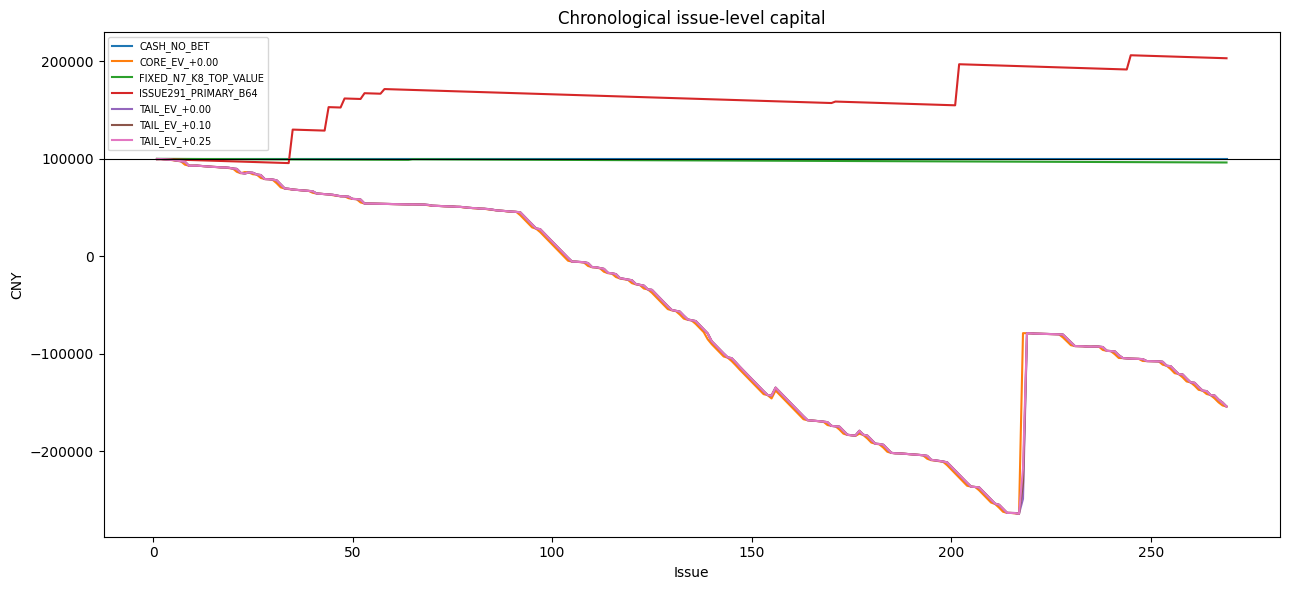

In [8]:
selected = summary[
    summary.policy.str.startswith(('DYNAMIC_','CORE_','TAIL_','BARBELL_'))
].nlargest(4, 'ex_largest_pnl_cny').policy.tolist()
selected += ['CASH_NO_BET','FIXED_N7_K8_TOP_VALUE','ISSUE291_PRIMARY_B64']
fig, ax = plt.subplots(figsize=(13, 6))
for policy, group in paths[paths.policy.isin(selected)].groupby('policy', sort=True):
    ax.plot(range(1, len(group)+1), group.capital_cny, label=policy)
ax.axhline(100_000, color='black', linewidth=.8)
ax.set(title='Chronological issue-level capital', xlabel='Issue', ylabel='CNY')
ax.legend(fontsize=7); plt.tight_layout()

## Decision

The strongest learned/barbell row by ex-largest P&L is `TAIL_EV_+0.00`: total P&L CNY11,422.51, ex-largest CNY-4,288.00, pre-tax ROI 265.39%, and bootstrap lower bound -100.00%. It remains an exploratory candidate unless it beats cash and named controls without relying on one jackpot. 2024+ is not opened by this notebook.